<a href="https://colab.research.google.com/github/3b232106/2026_DL_hws/blob/main/hw4_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 作業4-3 - 四資四乙 3B232106 陳威廷

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

## a. 資料預處理

讀入 CIFAR-10 數據集
* 總圖片數：60,000 張彩色影像（分成 訓練集 50,000 張、測試集 10,000 張）。
* 影像解析度：$32 \times 32$ 像素（RGB 3 通道）。
* 類別數量：10 個互斥類別（飛機、汽車、鳥、貓、鹿、狗、青蛙、馬、船、卡車），每類各 6,000 張。

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2925s 17us/step


In [3]:
(x_test_image,y_test_label)= cifar10.load_data()

In [4]:
x_train.shape

(50000, 32, 32, 3)

In [5]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [6]:
print(f"資料的最小值: {np.min(x_train)}")
print(f"資料的最大值: {np.max(x_train)}")

資料的最小值: 0
資料的最大值: 255


In [7]:
x_train = x_train/255
x_test = x_test/255

In [8]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [9]:
y_train.shape

(50000, 10)

In [10]:
# 資料類別標籤
labels_name = ["airplane(飛機)","automobile(汽車)","bird(鳥)","cat(貓)","deer(鹿)","dog(狗)","frog(青蛙)","horse(馬)","ship(船)","truck(卡車)"]

/tmp/ipykernel_1904/2094458755.py:9: UserWarning: Glyph 38738 (\N{CJK UNIFIED IDEOGRAPH-9752}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1904/2094458755.py:9: UserWarning: Glyph 34521 (\N{CJK UNIFIED IDEOGRAPH-86D9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1904/2094458755.py:9: UserWarning: Glyph 21345 (\N{CJK UNIFIED IDEOGRAPH-5361}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1904/2094458755.py:9: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38738 (\N{CJK UNIFIED IDEOGRAPH-9752}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34521 (\N{CJK UNIFIED IDEOGRAPH-86D9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byte

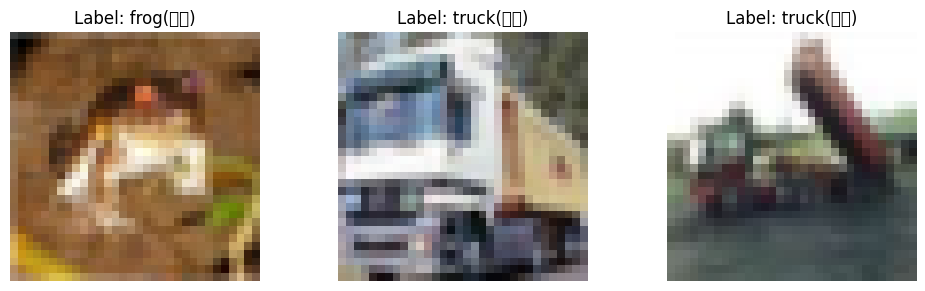

In [11]:
# 呈現訓練資料
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    label_index = np.argmax(y_train[i])
    plt.title(f"Label: {labels_name[label_index]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## b. 建立神經網路模型

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.layers import Dropout

In [13]:
model = Sequential()

In [14]:
# 第一層：卷積層32個Filter，尺寸大小(3,3)
model.add(Conv2D(32, (3, 3), padding='same',
        input_shape=(32, 32, 3),
        activation='relu')) # 參數個數: 32 * (3*3*3+1) = 896

# 第二層：dropout
model.add(Dropout(0.3))

# 第三層：卷積層32個Filter，尺寸大小(3,3)
model.add(Conv2D(32, (3, 3), padding='same',
        activation='relu')) # 參數個數: 32 * (3*3*32+1) = 9248

# 第四層：池化層，池化尺寸(2,2)
model.add(MaxPool2D())

# 第五層：卷積層64個Filter，尺寸大小(3,3)
model.add(Conv2D(64, (3, 3), padding='same',
        input_shape=(32, 32, 3),
        activation='relu')) # 參數個數: 64 * (3*3*32+1) = 18496

# 第六層：dropout
model.add(Dropout(0.3))

# 第七層：卷積層64個Filter，尺寸大小(3,3)
model.add(Conv2D(64, (3, 3), padding='same',
        input_shape=(32, 32, 3),
        activation='relu')) # 參數個數: 64 * (3*3*64+1) = 36928

# 第八層：池化層，池化尺寸(2,2)
model.add(MaxPool2D())

# 第九層：卷積層128個Filter，尺寸大小(3,3)
model.add(Conv2D(128, (3, 3), padding='same',
        input_shape=(32, 32, 3),
        activation='relu')) # 參數個數: 128 * (3*3*64+1) = 73856

# 第十層：dropout
model.add(Dropout(0.3))

# 第十一層：卷積層128個Filter，尺寸大小(3,3)
model.add(Conv2D(128, (3, 3), padding='same',
        input_shape=(32, 32, 3),
        activation='relu')) # 參數個數: 128 * (3*3*128+1) = 147584

# 第十二層：池化層，池化尺寸(2,2)
model.add(MaxPool2D())

# 第十三層：拉平層
model.add(Flatten())

# 第十四層：dropout
model.add(Dropout(0.3))

# 第十五層：全連接層：2500個神經元
model.add(Dense(2500, activation='relu')) # 參數個數: 2048 * 2500 + 2500 =5122500

# 第十六層：dropout
model.add(Dropout(0.3))

# 第十七層：全連接層：1500個神經元
model.add(Dense(1500, activation='relu')) # 參數個數: 2500 * 1500 + 1500 = 3751500

# 第十八層：dropout
model.add(Dropout(0.3))

# 第十九層：全連接層：10個神經元
model.add(Dense(10, activation='softmax')) # 參數個數: 1500 * 10 + 10 = 15010

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

## c. 訓練神經網路模型

In [15]:
model.compile(loss='categorical_crossentropy',
      optimizer=Adam(learning_rate=0.001),
      metrics=['accuracy'])

In [16]:
# 訓練資料中切出50%為驗證資料
train_history = model.fit(x_train, y_train, validation_split=0.2, batch_size=128, epochs=50)

Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 423s 1s/step - accuracy: 0.3411 - loss: 1.7671 - val_accuracy: 0.4336 - val_loss: 1.5290
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 440s 1s/step - accuracy: 0.5110 - loss: 1.3386 - val_accuracy: 0.5437 - val_loss: 1.2656
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 438s 1s/step - accuracy: 0.5857 - loss: 1.1423 - val_accuracy: 0.6258 - val_loss: 1.0360
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 443s 1s/step - accuracy: 0.6363 - loss: 1.0214 - val_accuracy: 0.6701 - val_loss: 0.9259
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 464s 1s/step - accuracy: 0.6691 - loss: 0.9298 - val_accuracy: 0.6855 - val_loss: 0.8986
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 413s 1s/step - accuracy: 0.6961 - loss: 0.8529 - val_accuracy: 0.7003 - val_loss: 0.8639
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 417s 1s/step - accuracy: 0.7197 - loss: 0.7951 - val_accuracy: 0.7263 - val_loss: 0.7868
Epoch 8/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 460s 1s/step - accuracy: 0.7410 - loss: 0.7345 - val_accu

## d. 以折線圖顯示訓練過程的 loss & accuracy

In [17]:
import matplotlib.pyplot as plt

# 畫出訓練過程每一個epoch訓練資料與驗證資料各自準確率(accuracy)的變化，或者損失誤差(loss)的變化
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

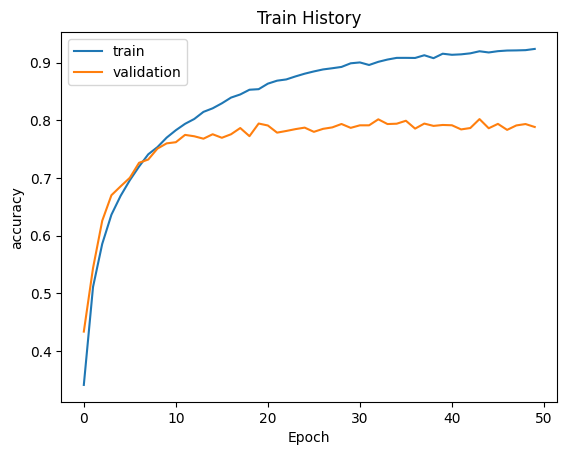

In [18]:
# 準確率(accuracy)
show_train_history(train_history,'accuracy','val_accuracy')

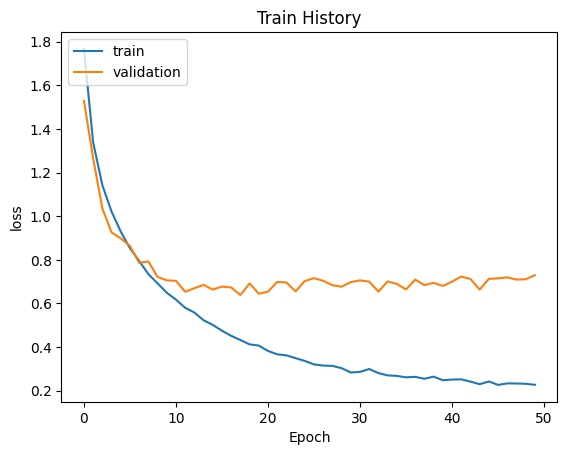

In [19]:
# 損失誤差(loss)
show_train_history(train_history,'loss','val_loss')

## e. 評估模型準確率

In [20]:
scores = model.evaluate(x_test, y_test)
print()
print('accuracy=',scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 83ms/step - accuracy: 0.7761 - loss: 0.7726

accuracy= 0.7760999798774719


## f. 進行預測

In [21]:
# 一次呈現數張測試資料(圖片)、預測結果與真實結果
def plot_images_labels_prediction(images, labels_onehot, prediction, idx, num=10):
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    if num > 25: num = 25

    labels = np.argmax(labels_onehot, axis=1)
    pred_labels = np.argmax(prediction, axis=1)

    for i in range(0, num):
        ax = plt.subplot(5, 5, 1 + i)
        ax.imshow(images[idx])

        title = "label=" + str(labels_name[labels[idx]]) + "\n"
        title += "predict=" + str(labels_name[pred_labels[idx]])

        ax.set_title(title, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        idx += 1
    plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35987 (\N{CJK UNIFIED IDEOGRAPH-8C93}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 33337 (\N{CJK UNIFIED IDEOGRAPH-8239}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 39131 (\N{CJK UNIFIED IDEOGRAPH-98DB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 40575 (\N{CJK UNIFIED IDEOGRAPH-9E7F}) missing from font(s) DejaVu Sans.
  fig.canvas

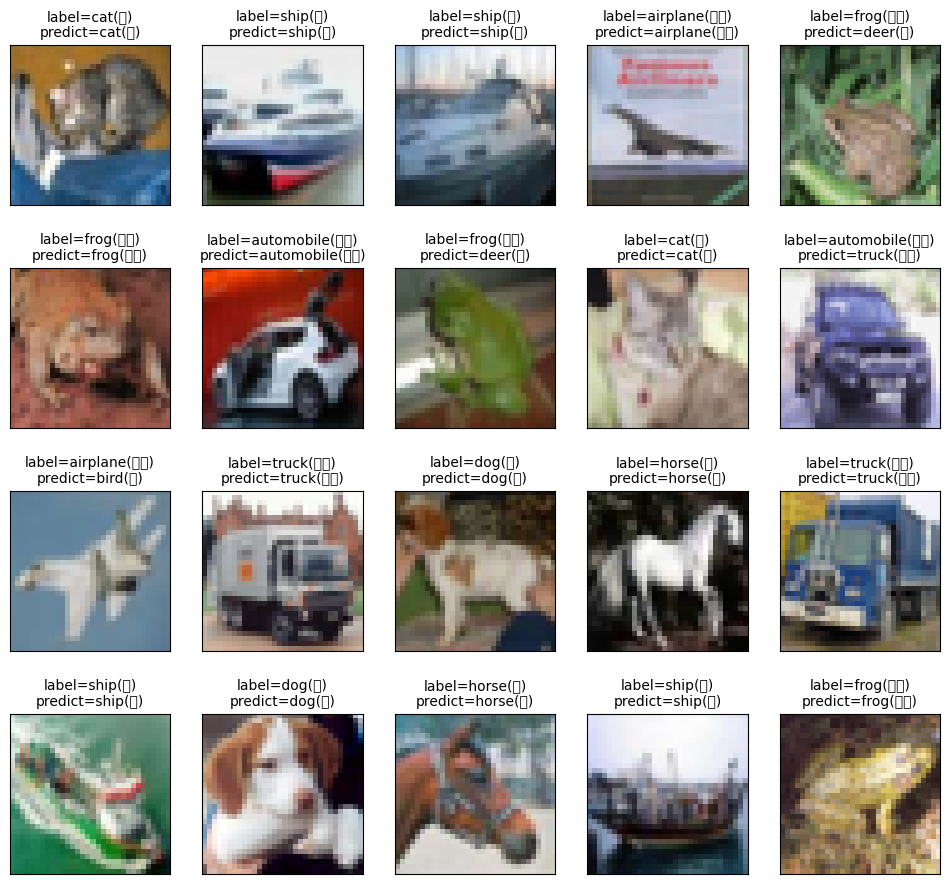

In [22]:
prediction = model.predict(x_test)
plot_images_labels_prediction(x_test,y_test,prediction,idx=0,num=20)

## g. 以混淆矩陣(Confusion matrix)呈現預測結果

In [23]:
import pandas as pd

# 把 one-hot y_test 轉換為整數標籤
true_labels = np.argmax(y_test, axis=1)

# 將10000個預測結果一一轉換為
predicted_labels = np.argmax(prediction, axis=1)

# Now use predicted_labels in crosstab
pd.crosstab(true_labels, predicted_labels, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,797,9,74,22,18,6,6,10,44,14
1,18,879,2,12,4,7,10,1,12,55
2,51,3,748,54,48,38,31,19,8,0
3,18,1,72,617,46,148,57,31,6,4
4,6,2,81,67,714,40,31,55,3,1
5,8,0,69,162,24,674,31,30,1,1
6,6,1,57,52,30,16,829,3,5,1
7,8,1,33,57,41,41,1,812,2,4
8,60,17,18,26,10,9,6,1,830,23


##　h. 儲存完整模型

In [24]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

%cd '/content/drive/My Drive/Colab Notebooks'

model.save('hw4-3.keras')

Mounted at /content/drive
/content/drive/My Drive/Colab Notebooks


##　i. interact_manual

In [25]:
y_predict = np.argmax(prediction, axis=1)

from ipywidgets import interact_manual
def test(test):
  plt.imshow(x_test[test], cmap='Greys')
  print('神經網路判斷為：', str(labels_name[y_predict[test]]))